# Task 5 — Gas Market Activity

## Analytical Question

**How did Ethereum's gas market activity change during the 30-day period?**

### Workflow

**BigQuery → GoogleSQL → Analytical Dataset → Pandas → Analysis → Visualization → Insight**

### Data source

Google Cloud BigQuery Ethereum Mainnet Blockchain Analytics dataset:
- **Source dataset:** `bigquery-public-data.goog_blockchain_ethereum_mainnet_us`
- **Source table:** `transactions`, `blocks`
- SQL: `sql/05_gas_activity.sql`

### Analysis window

- Start: **2026-08-24 10:01:35 UTC**
- End: **2026-09-23 10:01:35 UTC**
- Duration: **30 days**
- Start block: **25,824,304**
- End block: **26,039,452**

The first and last calendar dates are partial days because the window starts and ends at 10:01:35 UTC.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import pandas.io.formats.format as pf
# Force Pandas' internal integer formatter to use commas seperator globally
class CommaIntFormatter(pf._GenericArrayFormatter):
    def _format_strings(self):
        formatter = self.formatter or '{:,d}'.format
        return [formatter(x) for x in self.values]

# Override the default engine
pf._IntArrayFormatter = CommaIntFormatter

# Format float with comma(removes E-notation)
pd.set_option('display.float_format', lambda x: f' {x:,.2f}')

## Load the Analytical Dataset


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/daily_gas_activity.csv')
df['date'] = pd.to_datetime(df['date'])
df.head()


,date,avg_gas_price_gwei,median_gas_price_gwei,total_gas_used,avg_gas_used_per_block,avg_gas_limit,avg_gas_utilization_pct
0,2026-08-24,2.66,1.47,"126,843,024,122","30,345,221.08","59,996,618.39",50.58
1,2026-08-25,0.85,0.28,"218,050,922,535","30,394,608.66","59,996,697.13",50.66
2,2026-08-26,0.77,0.20,"217,769,296,656","30,363,817.16","59,996,377.27",50.61
3,2026-08-27,0.92,0.30,"218,437,823,137","30,423,095.14","59,996,438.66",50.71
4,2026-08-28,0.89,0.30,"218,212,568,813","30,425,623.09","59,996,744.99",50.71


## Validate the Analytical Dataset


In [3]:
print('Shape:', df.shape)
print('\nNull values:')
print(df.isnull().sum())
print('\nDuplicate dates:', df['date'].duplicated().sum())
print('\nDate range:', df['date'].min(), 'to', df['date'].max())


Shape: (31, 7)

Null values:
date                      0
avg_gas_price_gwei        0
median_gas_price_gwei     0
total_gas_used            0
avg_gas_used_per_block    0
avg_gas_limit             0
avg_gas_utilization_pct   0
dtype: int64

Duplicate dates: 0

Date range: 2026-08-24 00:00:00 to 2026-09-23 00:00:00


## Partial-Day Handling

The exact analysis window produces 31 calendar dates. The first and last dates are partial days and are excluded from comparable-day statistics.


In [4]:
# The two partial days
first_day = df["date"].min()
last_day = df["date"].max()

# keep only complete days
complete_days = df[(df["date"] > first_day) & (df["date"] < last_day)]
complete_days.shape

(29, 7)

In [5]:
# .copy() creates an independent DataFrame that we can safely modify.
complete_days = df[(df["date"] > first_day) & (df["date"] < last_day)].copy()

## Gas Price Analysis
> **Gas price** is the amount of ETH paid per unit of gas used to execute a transaction. It reflects the cost users are willing to pay for blockspace and is commonly measured in **Gwei**.

In [6]:
gas_price_summary = complete_days[['avg_gas_price_gwei', 'median_gas_price_gwei']].describe()
gas_price_summary


,avg_gas_price_gwei,median_gas_price_gwei
count,29.00,29.00
mean,0.81,0.26
std,0.14,0.13
min,0.46,0.06
25%,0.72,0.19
50%,0.80,0.25
75%,0.89,0.30
max,1.15,0.75


In [7]:
highest_avg_gas_price = complete_days.loc[complete_days['avg_gas_price_gwei'].idxmax()]
lowest_avg_gas_price = complete_days.loc[complete_days['avg_gas_price_gwei'].idxmin()]
print('Highest average gas price:')
print(highest_avg_gas_price[['date', 'avg_gas_price_gwei']])
print('\nLowest average gas price:')
print(lowest_avg_gas_price[['date', 'avg_gas_price_gwei']])


Highest average gas price:
date                  2026-09-21 00:00:00
avg_gas_price_gwei                   1.15
Name: 28, dtype: object

Lowest average gas price:
date                  2026-08-29 00:00:00
avg_gas_price_gwei                   0.46
Name: 5, dtype: object


## Gas Consumption
> **Gas consumption** is the total amount of gas actually used by transactions during a given period. It reflects how much computational work was executed on Ethereum.

In [8]:
gas_consumption_summary = complete_days[['total_gas_used', 'avg_gas_used_per_block']].describe()
gas_consumption_summary


,total_gas_used,avg_gas_used_per_block
count,29.00,29.00
mean,"217,766,324,884.72","30,364,544.01"
std,"525,772,966.05","49,856.36"
min,"216,553,109,908.00","30,274,835.51"
25%,"217,592,100,089.00","30,328,117.95"
50%,"217,854,521,065.00","30,364,888.52"
75%,"218,093,898,893.00","30,394,608.66"
max,"218,834,441,007.00","30,491,074.41"


In [9]:
highest_gas_consumption = complete_days.loc[complete_days['total_gas_used'].idxmax()]
lowest_gas_consumption = complete_days.loc[complete_days['total_gas_used'].idxmin()]
print('Highest daily gas consumption:')
print(highest_gas_consumption[['date', 'total_gas_used']])
print('\nLowest daily gas consumption:')
print(lowest_gas_consumption[['date', 'total_gas_used']])


Highest daily gas consumption:
date              2026-08-30 00:00:00
total_gas_used           218834441007
Name: 6, dtype: object

Lowest daily gas consumption:
date              2026-09-22 00:00:00
total_gas_used           216553109908
Name: 29, dtype: object


## Gas Utilization
> **Gas utilization** measures how much of the available block gas capacity was used. It is calculated as gas used relative to the block gas limit and expressed as a percentage.

In [10]:
utilization_summary = complete_days['avg_gas_utilization_pct'].describe()
utilization_summary


count    29.00
mean     50.61
std       0.08
min      50.46
25%      50.55
50%      50.61
75%      50.66
max      50.82
Name: avg_gas_utilization_pct, dtype: float64

## High-Gas Periods

Identify high-gas-price days using the 90th percentile of average daily gas price. This is a descriptive threshold.


In [11]:
gas_price_threshold = complete_days['avg_gas_price_gwei'].quantile(0.90)
high_gas_days = complete_days[complete_days['avg_gas_price_gwei'] >= gas_price_threshold].copy()

print('90th-percentile threshold:', gas_price_threshold)
high_gas_days[['date', 'avg_gas_price_gwei', 'median_gas_price_gwei', 'total_gas_used', 'avg_gas_utilization_pct']]


90th-percentile threshold: 0.9413322988090332


,date,avg_gas_price_gwei,median_gas_price_gwei,total_gas_used,avg_gas_utilization_pct
18,2026-09-11,0.97,0.28,"217,868,075,111",50.61
22,2026-09-15,1.13,0.25,"217,419,891,638",50.54
28,2026-09-21,1.15,0.75,"216,604,636,513",50.52


### Summary
**Gas price:** The cost paid per unit of gas, measured in Gwei.

**Gas consumption:** The total amount of gas used by transactions during the period.

**Gas utilization:** The percentage of available block gas capacity that was used.

## Rolling Averages


In [12]:
complete_days['avg_gas_price_7d'] = complete_days['avg_gas_price_gwei'].rolling(7).mean()
complete_days['gas_utilization_7d'] = complete_days['avg_gas_utilization_pct'].rolling(7).mean()
complete_days[['date', 'avg_gas_price_7d', 'gas_utilization_7d']].tail()


,date,avg_gas_price_7d,gas_utilization_7d
25,2026-09-18,0.89,50.57
26,2026-09-19,0.89,50.56
27,2026-09-20,0.87,50.54
28,2026-09-21,0.91,50.52
29,2026-09-22,0.87,50.51


## Visualization — Gas Price


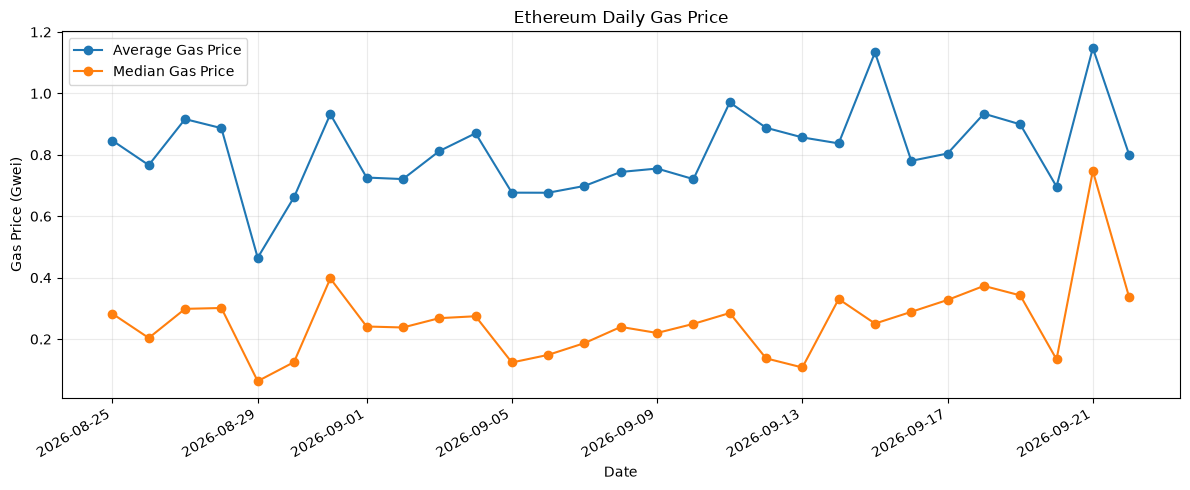

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(complete_days['date'], complete_days['avg_gas_price_gwei'], marker='o', label='Average Gas Price')
ax.plot(complete_days['date'], complete_days['median_gas_price_gwei'], marker='o', label='Median Gas Price')
ax.set_title('Ethereum Daily Gas Price')
ax.set_xlabel('Date')
ax.set_ylabel('Gas Price (Gwei)')
ax.legend()
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


C:\Users\yunus\anaconda3\envs\crypto-analytics\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


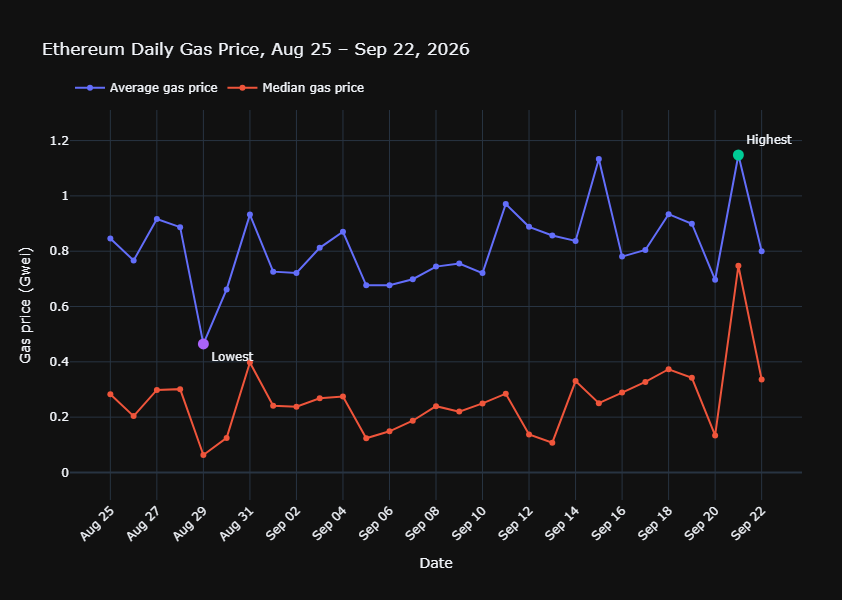

In [14]:
import plotly.express as px

# Prepare data for visualization
plot_df = complete_days[
    ["date", "avg_gas_price_gwei", "median_gas_price_gwei"]
].copy()

plot_df = plot_df.rename(
    columns={
        "avg_gas_price_gwei": "Average gas price",
        "median_gas_price_gwei": "Median gas price"
    }
)

plot_df = plot_df.melt(
    id_vars="date",
    var_name="metric",
    value_name="gas_price_gwei"
)

# Identify highest and lowest average gas-price days
highest_day = complete_days.loc[
    complete_days["avg_gas_price_gwei"].idxmax()
]

lowest_day = complete_days.loc[
    complete_days["avg_gas_price_gwei"].idxmin()
]

# Create the line chart
fig = px.line(
    plot_df,
    x="date",
    y="gas_price_gwei",
    color="metric",
    title="Ethereum Daily Gas Price, Aug 25 – Sep 22, 2026",
    markers=True,
    labels={
        "date": "Date",
        "gas_price_gwei": "Gas price (Gwei)",
        "metric": ""
    }
)

fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,
    margin=dict(l=70, r=40, t=110, b=100),
    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        tickmode="auto",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),
    yaxis=dict(
        title="Gas price (Gwei)",
        fixedrange=True
    ),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    )
)

fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "<b>%{fullData.name}</b>: "
        "%{y:.3f} Gwei"
        "<extra></extra>"
    )
)

# Highlight highest average gas-price day
fig.add_scatter(
    x=[highest_day["date"]],
    y=[highest_day["avg_gas_price_gwei"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Highest average gas price</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.3f} Gwei"
        "<extra></extra>"
    )
)

# Highlight lowest average gas-price day
fig.add_scatter(
    x=[lowest_day["date"]],
    y=[lowest_day["avg_gas_price_gwei"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Lowest average gas price</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.3f} Gwei"
        "<extra></extra>"
    )
)

# Add padding around the data
y_min = plot_df["gas_price_gwei"].min()
y_max = plot_df["gas_price_gwei"].max()
padding = (y_max - y_min) * 0.15

fig.update_yaxes(
    range=[
        y_min - padding,
        y_max + padding
    ]
)

fig.show()

## Visualization — Gas Consumption


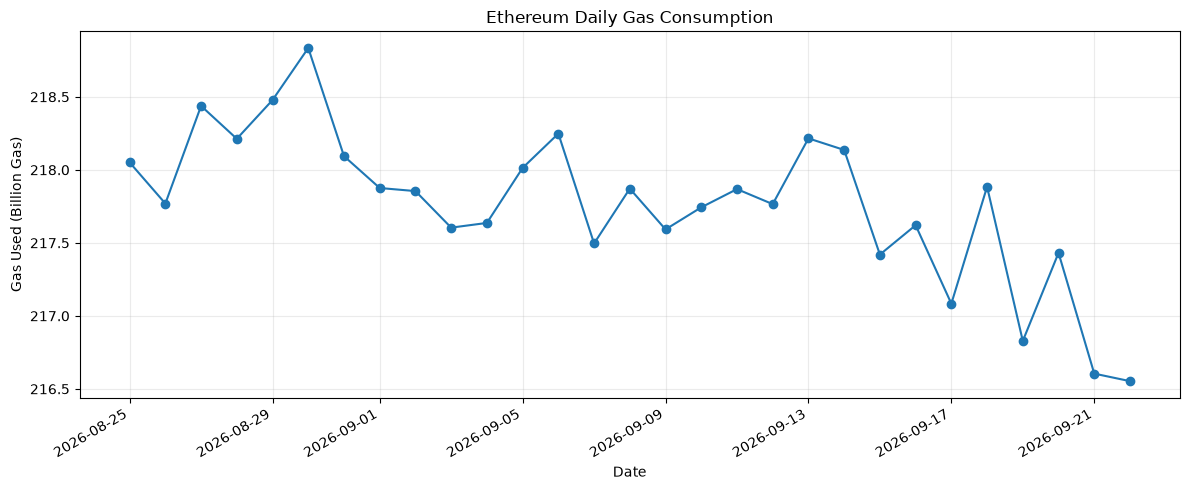

In [15]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(complete_days['date'], complete_days['total_gas_used'] / 1e9, marker='o')
ax.set_title('Ethereum Daily Gas Consumption')
ax.set_xlabel('Date')
ax.set_ylabel('Gas Used (Billion Gas)')
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


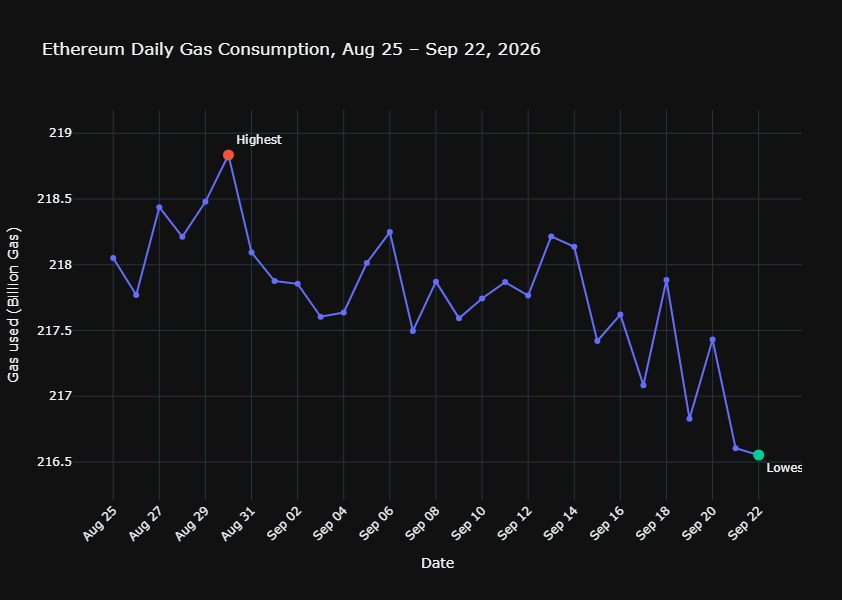

In [16]:
# Prepare data for visualization
plot_df = complete_days[
    ["date", "total_gas_used"]
].copy()

plot_df["gas_used_billion"] = plot_df["total_gas_used"] / 1e9

# Identify highest and lowest gas-consumption days
highest_day = plot_df.loc[
    plot_df["gas_used_billion"].idxmax()
]

lowest_day = plot_df.loc[
    plot_df["gas_used_billion"].idxmin()
]

# Create the line chart
fig = px.line(
    plot_df,
    x="date",
    y="gas_used_billion",
    title="Ethereum Daily Gas Consumption, Aug 25 – Sep 22, 2026",
    markers=True,
    labels={
        "date": "Date",
        "gas_used_billion": "Gas used (Billion)"
    }
)

fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,
    margin=dict(l=70, r=40, t=110, b=100),
    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        tickmode="auto",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),
    yaxis=dict(
        title="Gas used (Billion Gas)",
        fixedrange=True
    ),
    showlegend=False
)

fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "<b>%{x|%b %d, %Y}</b><br>"
        "%{y:.2f} billion gas"
        "<extra></extra>"
    )
)

# Highlight highest day
fig.add_scatter(
    x=[highest_day["date"]],
    y=[highest_day["gas_used_billion"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Highest gas consumption</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f} billion gas"
        "<extra></extra>"
    )
)

# Highlight lowest day
fig.add_scatter(
    x=[lowest_day["date"]],
    y=[lowest_day["gas_used_billion"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Lowest gas consumption</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f} billion gas"
        "<extra></extra>"
    )
)

# Add padding around the data
y_min = plot_df["gas_used_billion"].min()
y_max = plot_df["gas_used_billion"].max()
padding = (y_max - y_min) * 0.15

fig.update_yaxes(
    range=[
        y_min - padding,
        y_max + padding
    ]
)

fig.show()

## Visualization — Gas Utilization


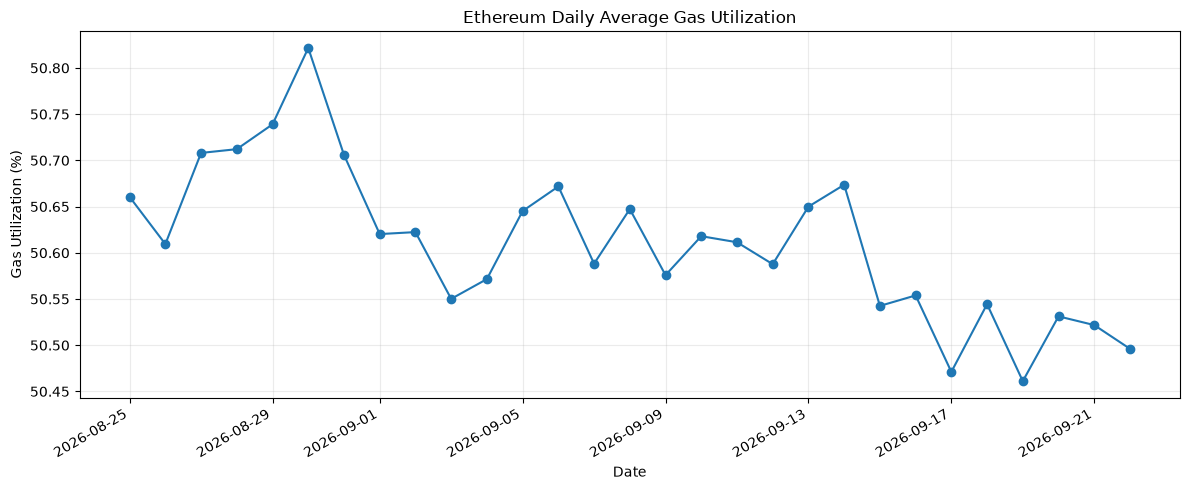

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(complete_days['date'], complete_days['avg_gas_utilization_pct'], marker='o')
ax.set_title('Ethereum Daily Average Gas Utilization')
ax.set_xlabel('Date')
ax.set_ylabel('Gas Utilization (%)')
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


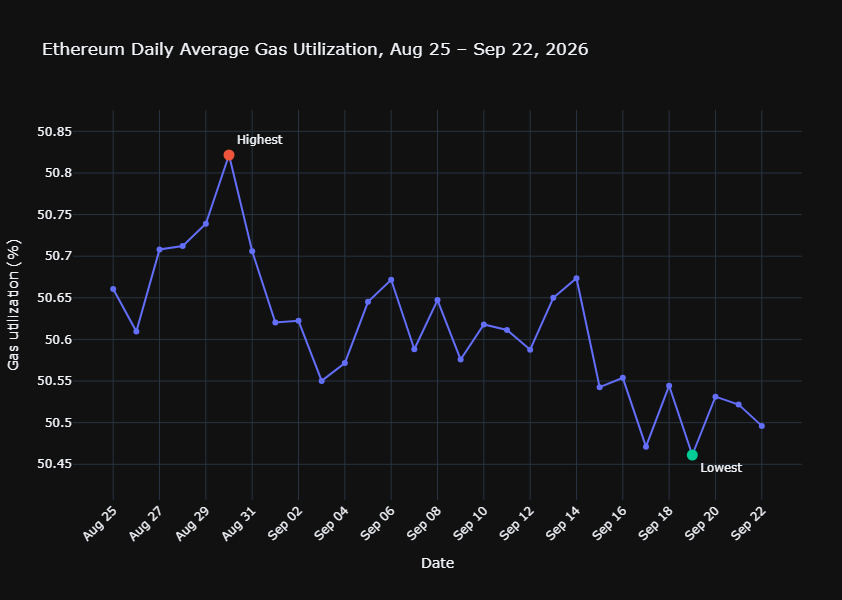

In [19]:
# Prepare data for visualization
plot_df = complete_days[
    ["date", "avg_gas_utilization_pct"]
].copy()

# Identify highest and lowest utilization days
highest_day = plot_df.loc[
    plot_df["avg_gas_utilization_pct"].idxmax()
]

lowest_day = plot_df.loc[
    plot_df["avg_gas_utilization_pct"].idxmin()
]

# Create the line chart
fig = px.line(
    plot_df,
    x="date",
    y="avg_gas_utilization_pct",
    title="Ethereum Daily Average Gas Utilization, Aug 25 – Sep 22, 2026",
    markers=True,
    labels={
        "date": "Date",
        "avg_gas_utilization_pct": "Gas utilization (%)"
    }
)

fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,
    margin=dict(l=70, r=40, t=110, b=100),
    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        tickmode="auto",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),
    yaxis=dict(
        title="Gas utilization (%)",
        fixedrange=True
    ),
    showlegend=False
)

fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "<b>%{x|%b %d, %Y}</b><br>"
        "%{y:.2f}%"
        "<extra></extra>"
    )
)

# Highlight highest utilization day
fig.add_scatter(
    x=[highest_day["date"]],
    y=[highest_day["avg_gas_utilization_pct"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Highest gas utilization</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f}%"
        "<extra></extra>"
    )
)

# Highlight lowest utilization day
fig.add_scatter(
    x=[lowest_day["date"]],
    y=[lowest_day["avg_gas_utilization_pct"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Lowest gas utilization</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f}%"
        "<extra></extra>"
    )
)

# Add padding around the data
y_min = plot_df["avg_gas_utilization_pct"].min()
y_max = plot_df["avg_gas_utilization_pct"].max()
padding = (y_max - y_min) * 0.15

fig.update_yaxes(
    range=[
        y_min - padding,
        y_max + padding
    ]
)

fig.show()

## Finding | Evidence | Meaning

### Finding
Gas prices exhibited considerably greater variability than gas consumption and blockspace utilization during the 30-day period.

### Evidence
Average gas price had a coefficient of variation of **17.18%**, compared with **0.24%** for daily gas consumption and **0.16%** for average gas utilization.

Average gas price ranged from **0.465 Gwei on August 29** to **1.148 Gwei on September 21**. Daily gas consumption ranged from approximately **216.55 billion gas on September 22** to **218.83 billion gas on August 30**, while average gas utilization remained between **50.46% and 50.82%**.

**Meaning Ethereum's daily computational demand remained relatively stable during the period, while the price paid for that blockspace fluctuated more substantially. Therefore, changes in gas price should not be interpreted as direct changes in network demand or blockspace utilization.

### High-Gas Periods

Using the **90th percentile of average daily gas price (0.941 Gwei)** as a descriptive threshold, three complete days were identified as high-gas-price periods:

- **September 11:** 0.971 Gwei
- **September 15:** 1.133 Gwei
- **September 21:** 1.148 Gwei

These dates identify periods of relatively elevated gas prices within this dataset; the analysis does not establish the causes of those increases.


## Limitations

- The analysis covers only a **30-day period**, so the observed gas-market patterns do not establish longer-term trends.

- **Gas price, gas consumption, and gas utilization measure different aspects of network activity.** Changes in one metric do not necessarily imply a corresponding change in the others.

- The **first and last calendar dates are partial days** and were excluded from the comparable daily analysis. The analysis identifies patterns in gas activity but does not establish their underlying causes.